# Экзаменационная задача №16. Расчёт оптимальной стратегии участия в аукционе

**Дисциплина:** Экономика информатизации, лекция №17
**Студент:** Грошев Степан Сергеевич, группа БИ 5-1
**Дата:** 2026-11-12

In [1]:
# ======================================================================
# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №16: РАСЧЁТ ОПТИМАЛЬНОЙ СТРАТЕГИИ УЧАСТИЯ В АУКЦИОНЕ
# ======================================================================
# Дисциплина: Экономика информатизации (лекция №17)
# Дата: 2026-11-12
# Студент: Грошев Степан Сергеевич
# Группа: БИ 5-1
# ======================================================================

# Подключение библиотек и общих утилит проекта
import sys, math
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # корень репозитория: utils/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils.calculations import npv, irr, payback_period, discounted_payback_period, present_values, annuity_factor, fmt_rub
from utils.visualization import setup_style, thousands_axis, bar_labels, tornado, PALETTE
setup_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}".replace(",", " "))
pd.set_option("display.width", 140)

## 1. Экономическая постановка задачи

Подрядчик участвует в электронном аукционе по 44-ФЗ: НМЦК 50 млн руб., его затраты 35 млн руб.
Чем ниже цена, тем больше шанс выиграть, но тем меньше прибыль при победе. Слишком низкая цена означает убыток
и антидемпинговые санкции. Нужно найти цену с максимальной **ожидаемой полезностью** (ожидаемой прибылью) и оценить риски.

Тема лекции №17: теория игр в госзакупках, полезность участника $U=(P-C)\cdot\Pr(\text{победа})$, оптимальная ставка,
демпинг и антидемпинговые меры (ст. 37 44-ФЗ), проклятие победителя для подрядчика.

## 2. Исходные данные

In [2]:
C = 35.0          # затраты подрядчика, млн руб.
NMCK = 50.0       # НМЦК, млн руб.
n = 5             # участников (уже учтено в функции вероятности победы)
dump_threshold, dump_penalty = 30.0, 5.0     # штраф за демпинг при P < 30
pr_win = lambda P: np.clip(1 - P / NMCK, 0, 1)
pd.DataFrame({"Параметр": ["Затраты C", "НМЦК", "Участников", "Вероятность победы", "Штраф за демпинг"],
              "Значение": ["35 млн руб.", "50 млн руб.", "5", "Pr = 1 − P/50", "5 млн руб. при P < 30"]})

,Параметр,Значение
0,Затраты C,35 млн руб.
1,НМЦК,50 млн руб.
2,Участников,5
3,Вероятность победы,Pr = 1 − P/50
4,Штраф за демпинг,5 млн руб. при P < 30


**Допущения:** штраф за демпинг платится, если цена ниже 30 млн руб., даже без победы (наказание за саму заявку).
Вероятность победы дана в условии и уже учитывает 5 конкурентов. В основном расчёте подрядчик нейтрален к риску,
отдельно смотрим осторожного подрядчика.

## 3. Математическая модель

$$U(P) = (P - C)\cdot\Big(1-\frac{P}{50}\Big) - 5\cdot\mathbb{1}[P<30] \to \max_P$$
При $P\ge30$: $\dfrac{dU}{dP} = \Big(1-\dfrac{P}{50}\Big) - \dfrac{P-C}{50} = 0 \Rightarrow P^* = \dfrac{50 + C}{2} = 42{,}5$ млн руб.

Риск оцениваем по дисперсии результата $\mathrm{Var}=(P-C)^2\,p(1-p)$, где $p=\Pr(\text{победа})$, и через функцию полезности
$u(x) = 1-e^{-ax}$ для осторожного подрядчика.
Антидемпинговая норма 44-ФЗ (ст. 37): при снижении цены на 25 % и больше от НМЦК ($P\le37{,}5$) нужно обеспечение в 1,5 раза
больше или подтверждение добросовестности.

## 4. Реализация расчёта
### 4.1. Полезность при разных ценах

In [3]:
def utility(P, cost=C):
    return (P - cost) * pr_win(P) - dump_penalty * (P < dump_threshold)

prices = np.arange(25, 50.1, 2.5)
tab = pd.DataFrame({"Цена P, млн": prices})
tab["Снижение от НМЦК"] = 1 - tab["Цена P, млн"] / NMCK
tab["Pr(победа)"] = pr_win(tab["Цена P, млн"])
tab["Прибыль при победе"] = tab["Цена P, млн"] - C
tab["Штраф"] = np.where(tab["Цена P, млн"] < dump_threshold, dump_penalty, 0)
tab["Ожид. полезность U"] = utility(tab["Цена P, млн"])
tab["Антидемпинг 44-ФЗ"] = np.where(tab["Цена P, млн"] <= 0.75 * NMCK, "да (обеспечение ×1,5)", "нет")
tab.round(3)

,"Цена P, млн",Снижение от НМЦК,Pr(победа),Прибыль при победе,Штраф,Ожид. полезность U,Антидемпинг 44-ФЗ
0,25.00,0.50,0.50,-10.00,5.00,-10.00,"да (обеспечение ×1,5)"
1,27.50,0.45,0.45,-7.50,5.00,-8.38,"да (обеспечение ×1,5)"
2,30.00,0.40,0.40,-5.00,0.00,-2.00,"да (обеспечение ×1,5)"
3,32.50,0.35,0.35,-2.50,0.00,-0.88,"да (обеспечение ×1,5)"
4,35.00,0.30,0.30,0.00,0.00,0.00,"да (обеспечение ×1,5)"
5,37.50,0.25,0.25,2.50,0.00,0.62,"да (обеспечение ×1,5)"
6,40.00,0.20,0.20,5.00,0.00,1.00,нет
7,42.50,0.15,0.15,7.50,0.00,1.12,нет
8,45.00,0.10,0.10,10.00,0.00,1.00,нет
9,47.50,0.05,0.05,12.50,0.00,0.62,нет


### 4.2. Оптимальная цена

In [4]:
grid = np.linspace(20, 50, 30001)
U = utility(grid)
P_opt = grid[U.argmax()]
P_analytic = (NMCK + C) / 2
print(f"Оптимальная цена (численно): {P_opt:.2f} млн руб.;  аналитически: (50 + 35)/2 = {P_analytic:.2f}")
print(f"Pr(победа) = {pr_win(P_opt):.0%};  прибыль при победе = {P_opt - C:.2f} млн ({(P_opt - C)/P_opt:.1%} от цены)")
print(f"Ожидаемая полезность U* = {U.max():.3f} млн руб.;  снижение от НМЦК = {1 - P_opt/NMCK:.0%}")

Оптимальная цена (численно): 42.50 млн руб.;  аналитически: (50 + 35)/2 = 42.50
Pr(победа) = 15%;  прибыль при победе = 7.50 млн (17.6% от цены)
Ожидаемая полезность U* = 1.125 млн руб.;  снижение от НМЦК = 15%


### 4.3. Оценка рисков

In [5]:
risk = tab[tab["Цена P, млн"] >= 35].copy()
p = risk["Pr(победа)"]
risk["Ст. откл. результата"] = (risk["Цена P, млн"] - C) * np.sqrt(p * (1 - p))
risk["Коэфф. вариации"] = risk["Ст. откл. результата"] / risk["Ожид. полезность U"].replace(0, np.nan)
display(risk[["Цена P, млн", "Pr(победа)", "Ожид. полезность U", "Ст. откл. результата", "Коэфф. вариации"]].round(3))

# Несклонный к риску подрядчик: экспоненциальная полезность, гарантированный эквивалент
def certainty_equiv(P, a):
    pw = pr_win(P); x = P - C
    eu = pw * (1 - np.exp(-a * x)) + (1 - pw) * 0 - 0
    return -np.log(1 - eu) / a
for a in [0.05, 0.2, 0.5]:
    ce = certainty_equiv(grid[grid >= 35], a)
    print(f"Коэфф. неприятия риска a = {a}: оптимальная цена {grid[grid >= 35][ce.argmax()]:.2f} млн руб.")

# Неопределённость собственных затрат (проклятие победителя для подрядчика)
rows = []
for c_real in [32, 35, 38, 41]:
    rows.append({"Фактические затраты, млн": c_real, "Оптим. цена при известных затратах": (NMCK + c_real) / 2,
                 "Прибыль при победе по цене 42,5": 42.5 - c_real,
                 "U при цене 42,5": utility(np.array([42.5]), cost=c_real)[0]})
pd.DataFrame(rows).round(3)

,"Цена P, млн",Pr(победа),Ожид. полезность U,Ст. откл. результата,Коэфф. вариации
4,35.00,0.30,0.00,0.00,NaN
5,37.50,0.25,0.62,1.08,1.73
6,40.00,0.20,1.00,2.00,2.00
7,42.50,0.15,1.12,2.68,2.38
8,45.00,0.10,1.00,3.00,3.00
9,47.50,0.05,0.62,2.72,4.36
10,50.00,0.00,0.00,0.00,NaN


Коэфф. неприятия риска a = 0.05: оптимальная цена 41.84 млн руб.
Коэфф. неприятия риска a = 0.2: оптимальная цена 40.37 млн руб.
Коэфф. неприятия риска a = 0.5: оптимальная цена 38.78 млн руб.


,"Фактические затраты, млн",Оптим. цена при известных затратах,"Прибыль при победе по цене 42,5","U при цене 42,5"
0,32,41.00,10.50,1.57
1,35,42.50,7.50,1.12
2,38,44.00,4.50,0.68
3,41,45.50,1.50,0.23


## 5. Визуализация результатов

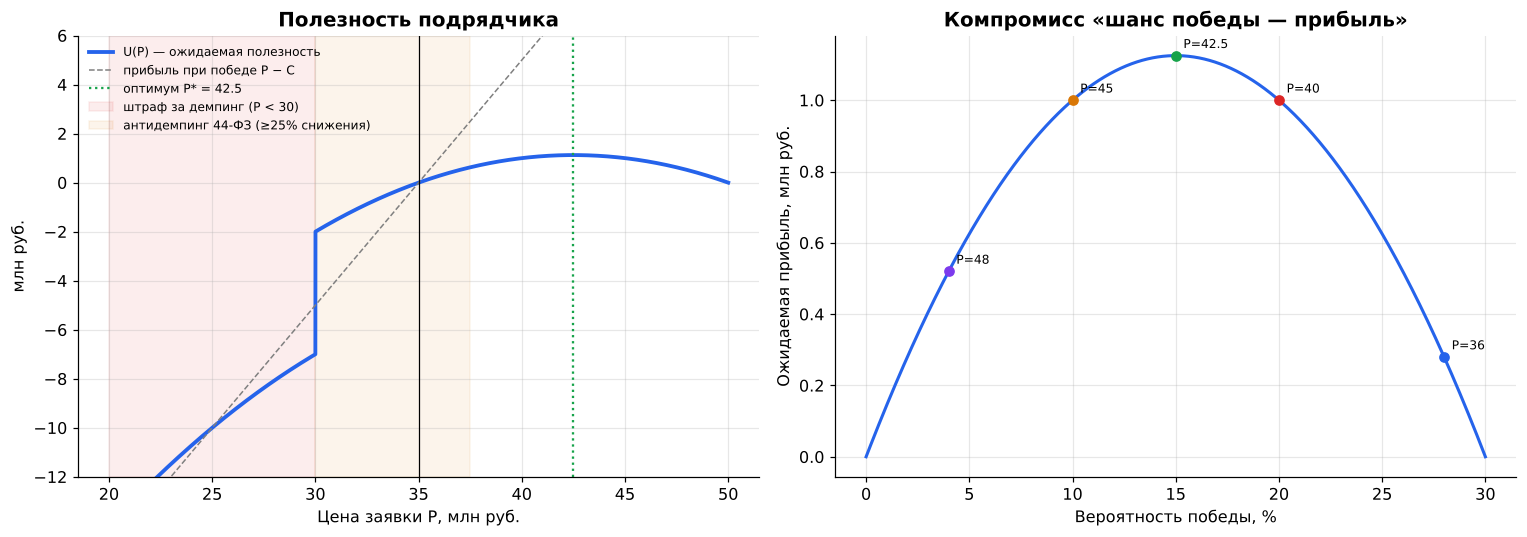

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
ax.plot(grid, U, lw=2.5, label="U(P) — ожидаемая полезность")
ax.plot(grid, (grid - C), lw=1, ls="--", color="gray", label="прибыль при победе P − C")
ax.axvline(P_opt, color=PALETTE[2], ls=":", label=f"оптимум P* = {P_opt:.1f}")
ax.axvspan(20, dump_threshold, color=PALETTE[1], alpha=0.08, label="штраф за демпинг (P < 30)")
ax.axvspan(dump_threshold, 37.5, color=PALETTE[3], alpha=0.08, label="антидемпинг 44-ФЗ (≥25% снижения)")
ax.axvline(C, color="black", lw=0.8)
ax.set_ylim(-12, 6); ax.set_xlabel("Цена заявки P, млн руб."); ax.set_ylabel("млн руб."); ax.set_title("Полезность подрядчика")
ax.legend(fontsize=8)
ax = axes[1]
ax.plot(pr_win(grid[grid >= 35]) * 100, utility(grid[grid >= 35]), lw=2)
for P_ in [36, 40, 42.5, 45, 48]:
    ax.scatter(pr_win(P_) * 100, utility(np.array([P_]))[0], zorder=3); ax.annotate(f"P={P_}", (pr_win(P_) * 100, utility(np.array([P_]))[0]), xytext=(5, 5), textcoords="offset points", fontsize=8)
ax.set_xlabel("Вероятность победы, %"); ax.set_ylabel("Ожидаемая прибыль, млн руб."); ax.set_title("Компромисс «шанс победы — прибыль»")
plt.tight_layout(); plt.show()

## 6. Интерпретация результатов

- **Лучшая цена 42,5 млн руб.** (на 15 % ниже НМЦК): шанс победы 15 %, прибыль при победе 7,5 млн руб. (17,6 % цены),
  ожидаемая полезность около 1,13 млн руб. График полезности это парабола с вершиной ровно посередине между затратами и НМЦК.
- **Демпинговать бессмысленно:** любая цена ниже 35 млн руб. даёт убыток при победе, а ниже 30 ещё и штраф 5 млн руб.
  Особенность условия: порог штрафа (30) ниже затрат (35), поэтому разумный подрядчик до него вообще не дойдёт,
  и на оптимум штраф не влияет.
- **Антидемпинговые меры 44-ФЗ** начинаются при снижении от 25 % (цена до 37,5 млн руб.). Наша цена 42,5 млн руб.
  в эту зону не попадает, дополнительное обеспечение не нужно.
- **Риск:** ожидаемая прибыль маленькая по сравнению с разбросом (шанс победы всего 15 %), поэтому подрядчику нужно участвовать
  в нескольких аукционах. Осторожный подрядчик выберет цену **ниже** (39–42 млн руб., смотря насколько он боится риска):
  он отдаёт часть прибыли за больший шанс получить контракт и меньший разброс. Но и он не заходит в антидемпинговую зону.
- **Если затраты посчитаны неверно:** при реальных затратах 41 млн руб. прибыль при цене 42,5 упадёт до 1,5 млн руб.
  Ошибиться в своих затратах опаснее, чем немного ошибиться с ценой.

## 7. Выводы и рекомендации

1. Подать заявку примерно на **42,5 млн руб.** (−15 % от НМЦК). Во время торгов не опускаться ниже **37,5–38 млн руб.**
   (антидемпинговая зона и почти нулевая прибыль) и никогда ниже затрат 35 млн руб.
2. До торгов уточнить смету с резервом на риски 5–10 %: ошибка в затратах съедает всю прибыль.
3. Участвовать во многих аукционах: при шансе 15 % на один аукцион нужно 7–10 аукционов в год, чтобы стабильно получать контракты.
4. Если конкуренты опускают цену до 35–37 млн руб., лучше выйти из торгов, чем выиграть контракт без прибыли
   (проклятие победителя для подрядчика).